# Submission 1: Dataset, EDA and Related Work
**Dataset:** SkinDisNet (skin disease photos, 6 classes)

This notebook has three parts:
- **A.** Dataset information
- **B.** Exploratory data analysis (EDA)
- **C.** Related work summary

## A. Dataset information

| Item | Details |
|---|---|
| Name | SkinDisNet: A Multi-Class Clinical Images and Metadata for Skin Disease |
| Source link | https://data.mendeley.com/datasets/yj3md44hxg/2 (DOI 10.17632/yj3md44hxg.2) |
| Dataset paper | Sultana et al., *Data in Brief* 63 (2025) 112239, https://doi.org/10.1016/j.dib.2025.112239 |
| Licence | CC BY-NC 4.0 (free to use, but not for commercial purposes) |
| Year | 2025 (version 2 published on 26 June 2025) |
| Task type | Multi-class image classification |
| Number of classes | 6 |
| Classes | AD = Atopic Dermatitis, CD = Contact Dermatitis, EC = Eczema, SC = Scabies, SD = Seborrheic Dermatitis, TC = Tinea Corporis |
| Total images | 1,710 original photos (Preprocessed folder) + 11,970 augmented copies (Augmented folder). Each original has 7 augmented copies. |
| Per-class counts | Shown in the table printed by the first code cell below |
| Image size, channels, format | 512 x 512 pixels, 3 channels (RGB), JPEG (checked in the code below) |
| Extra data | One CSV file with 7 columns (patient id, image id, age, sex, lesion location, diagnosis, folder name). 416 patients in total. |
| How it was collected | Smartphone photos taken during consultations at two hospitals in Bangladesh (Rangpur Medical College and Shahid Syed Nazrul Islam Medical College) |

The download has two folders (`SkinDisNet` and `SkinDisNet_2`) with the same class counts. This notebook uses `SkinDisNet_2` because it also contains the metadata CSV.

**Why this dataset matters (medical domain):**
- Skin diseases are very common in Bangladesh and South Asia, but there are not enough skin specialists for everyone.
- Photos from a normal smartphone are cheap to collect, so a model trained on them could help with early screening in places without a specialist.
- Scabies and tinea corporis are infections that spread between people, so finding them early also helps stop the spread.
- A dataset from Bangladeshi hospitals adds local data, because many public skin datasets come from other countries.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

plt.rcParams["figure.dpi"] = 80
random.seed(42)
np.random.seed(42)

DATA_DIR = "/Users/macbook/Desktop/projects/SkinDisNet A Multi-Class Clinical Images and Metad/SkinDisNet_2"
IMG_EXT = (".jpg", ".jpeg", ".png")

CLASS_NAMES = {
    "AD": "Atopic Dermatitis",
    "CD": "Contact Dermatitis",
    "EC": "Eczema",
    "SC": "Scabies",
    "SD": "Seborrheic Dermatitis",
    "TC": "Tinea Corporis",
}

folders = {name.lower(): os.path.join(DATA_DIR, name)
           for name in os.listdir(DATA_DIR)
           if os.path.isdir(os.path.join(DATA_DIR, name))}
PRE_DIR = folders["preprocessed"]
AUG_DIR = folders["augmented"]


def list_images(stage_dir):
    rows = []
    for class_folder in sorted(os.listdir(stage_dir)):
        class_path = os.path.join(stage_dir, class_folder)
        if not os.path.isdir(class_path):
            continue
        if "(" in class_folder:
            code = class_folder.split("(")[-1].strip(")")
        else:
            code = class_folder
        for file in os.listdir(class_path):
            if file.lower().endswith(IMG_EXT):
                rows.append({"class": code, "path": os.path.join(class_path, file)})
    return pd.DataFrame(rows)


pre = list_images(PRE_DIR)
aug = list_images(AUG_DIR)

counts = pd.DataFrame({
    "Original images (Preprocessed)": pre["class"].value_counts(),
    "Augmented images": aug["class"].value_counts(),
}).sort_index()
counts.insert(0, "Disease", [CLASS_NAMES.get(c, c) for c in counts.index])
counts.loc["Total"] = ["", counts.iloc[:, 1].sum(), counts.iloc[:, 2].sum()]

print("Number of classes:", pre["class"].nunique())
print("Total images:", len(pre) + len(aug), "(", len(pre), "original +", len(aug), "augmented )")
display(counts)

Number of classes: 6
Total images: 13680 ( 1710 original + 11970 augmented )


,Disease,Original images (Preprocessed),Augmented images
class,,,
AD,Atopic Dermatitis,70,490
CD,Contact Dermatitis,477,3339
EC,Eczema,466,3262
SC,Scabies,343,2401
SD,Seborrheic Dermatitis,79,553
TC,Tinea Corporis,275,1925
Total,,1710,11970


In [2]:
def check_images(df):
    sizes, modes, formats = set(), set(), set()
    total_bytes = 0
    for path in df["path"]:
        with Image.open(path) as img:
            sizes.add(img.size)
            modes.add(img.mode)
            formats.add(img.format)
        total_bytes += os.path.getsize(path)
    return sizes, modes, formats, total_bytes / 1024 / 1024


for name, df in [("Preprocessed", pre), ("Augmented", aug)]:
    sizes, modes, formats, mb = check_images(df)
    print(name)
    print("  image sizes (width, height):", sizes)
    print("  colour mode (RGB = 3 channels):", modes)
    print("  file format:", formats)
    print("  folder size: %.0f MB" % mb)

csv_files = [f for f in os.listdir(DATA_DIR) if f.lower().endswith(".csv")]
meta = pd.read_csv(os.path.join(DATA_DIR, csv_files[0]))
print("\nMetadata file:", csv_files[0], "| rows, columns:", meta.shape)
print("Number of patients:", meta["Patient_id"].nunique())
display(meta.head())

Preprocessed
  image sizes (width, height): {(512, 512)}
  colour mode (RGB = 3 channels): {'RGB'}
  file format: {'JPEG'}
  folder size: 47 MB
Augmented
  image sizes (width, height): {(512, 512)}
  colour mode (RGB = 3 channels): {'RGB'}
  file format: {'JPEG'}
  folder size: 1303 MB

Metadata file: SkinDisNet_Metadata.csv | rows, columns: (1710, 7)
Number of patients: 416


,Folder_name,Patient_id,Image_id,Age,Sex,Leision_location,Diagnosis
0,Atopic Dermatitis (AD),P_001,AD (1),14.0,Female,Hand,Atopic Dermatitis
1,Atopic Dermatitis (AD),P_001,AD (2),14.0,Female,Hand,Atopic Dermatitis
2,Atopic Dermatitis (AD),P_001,AD (3),14.0,Female,Finger,Atopic Dermatitis
3,Atopic Dermatitis (AD),P_001,AD (4),14.0,Female,Finger,Atopic Dermatitis
4,Atopic Dermatitis (AD),P_001,AD (5),14.0,Female,Hand,Atopic Dermatitis


## B. Exploratory data analysis (EDA)

### B1. Class distribution

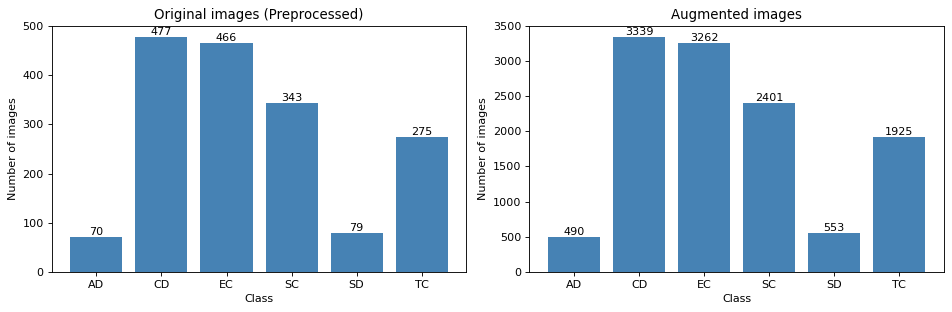

Share of each class in the original images (%):
class
AD     4.1
CD    27.9
EC    27.3
SC    20.1
SD     4.6
TC    16.1

Largest class : CD 477
Smallest class: AD 70
Largest / smallest = 6.81
Is the data imbalanced? YES


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (title, df) in zip(axes, [("Original images (Preprocessed)", pre), ("Augmented images", aug)]):
    class_counts = df["class"].value_counts().sort_index()
    bars = ax.bar(class_counts.index, class_counts.values, color="steelblue")
    ax.bar_label(bars)
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of images")

plt.tight_layout()
plt.show()

class_counts = pre["class"].value_counts()
share = (class_counts / class_counts.sum() * 100).round(1)
ratio = class_counts.max() / class_counts.min()

print("Share of each class in the original images (%):")
print(share.sort_index().to_string())
print()
print("Largest class :", class_counts.idxmax(), class_counts.max())
print("Smallest class:", class_counts.idxmin(), class_counts.min())
print("Largest / smallest = %.2f" % ratio)
print("Is the data imbalanced?", "YES" if ratio > 1.5 else "NO")

**Answer:** the data is **imbalanced**. Contact Dermatitis (CD) has the most images and Atopic Dermatitis (AD) has the fewest, about 6.8 times fewer. The augmented folder keeps the same imbalance because every class was augmented 7 times.

### B2. Sample images (5 per class)

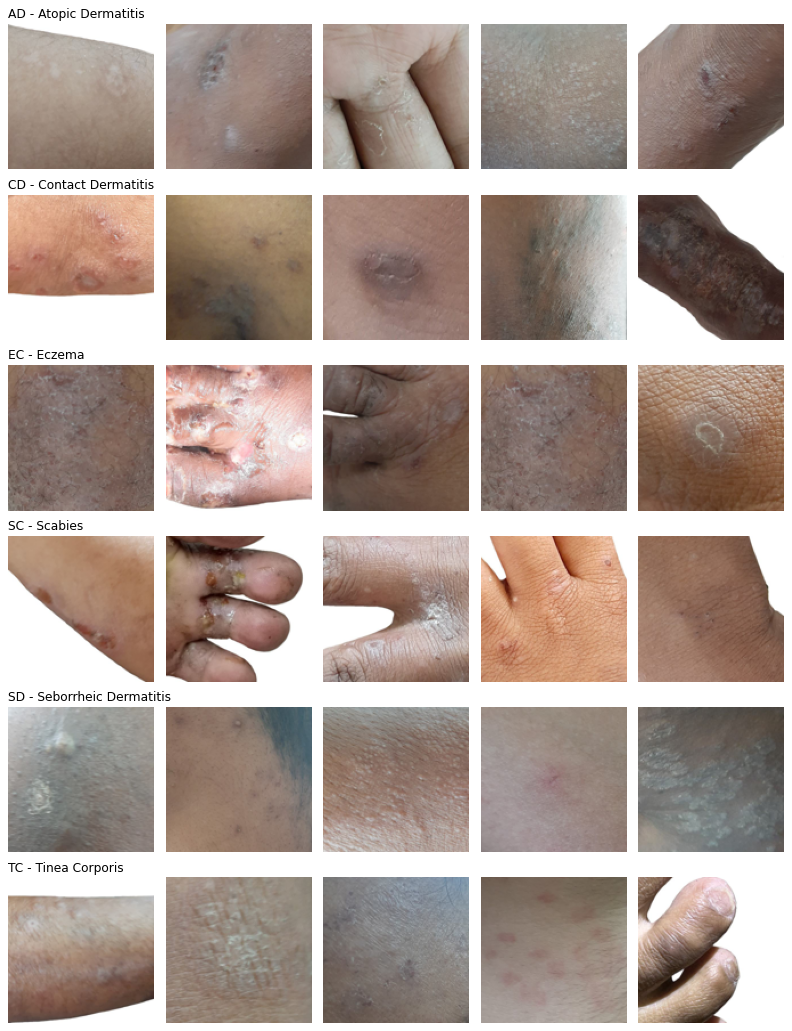

In [4]:
classes = sorted(pre["class"].unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(10, 13))

for row, cls in enumerate(classes):
    paths = pre[pre["class"] == cls]["path"].sample(5, random_state=42).tolist()
    for col, path in enumerate(paths):
        with Image.open(path) as img:
            img = img.convert("RGB")
            img.thumbnail((128, 128))
            axes[row, col].imshow(np.array(img))
        axes[row, col].axis("off")
    axes[row, 0].set_title(cls + " - " + CLASS_NAMES.get(cls, cls), loc="left", fontsize=11)

plt.tight_layout()
plt.show()

### B3. Image quality check (brightness and sharpness)
Smartphone photos can be too dark, too bright or blurry. For every original image the code below measures:
- **Brightness:** the average grey level (0 = black, 255 = white).
- **Sharpness:** how much fine detail is in the image. A low number means a blurry image.

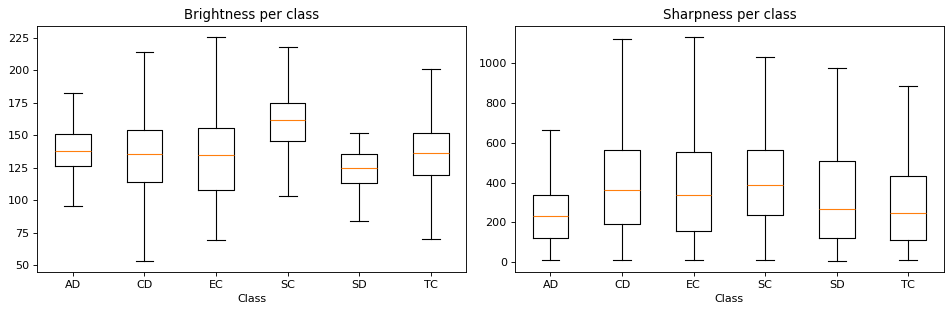

,brightness,sharpness
class,,
AD,139.399994,270.200012
CD,133.399994,424.100006
EC,134.899994,455.399994
SC,160.000000,425.600006
SD,124.000000,352.600006
TC,135.300003,308.899994


In [5]:
def brightness_and_sharpness(path):
    with Image.open(path) as img:
        img.draft("L", (256, 256))
        gray = np.array(img.convert("L").resize((128, 128)), dtype=np.float32)
    laplacian = (4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1]
                 - gray[1:-1, :-2] - gray[1:-1, 2:])
    return gray.mean(), laplacian.var()


values = [brightness_and_sharpness(p) for p in pre["path"]]
quality = pre[["class"]].copy()
quality["brightness"] = [v[0] for v in values]
quality["sharpness"] = [v[1] for v in values]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["brightness", "sharpness"]):
    data = [quality.loc[quality["class"] == c, column] for c in classes]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels(classes)
    ax.set_title(column.capitalize() + " per class")
    ax.set_xlabel("Class")
plt.tight_layout()
plt.show()

display(quality.groupby("class")[["brightness", "sharpness"]].mean().round(1))

### B4. Short written findings

**1. Class imbalance.** CD (477 images), EC (466) and SC (343) are large classes. AD (70) and SD (79) are very small. If I train normally, the model will favour the big classes and accuracy alone will look better than it is.
- **What I will do:** use class weights in the loss, keep the class ratio the same in train, validation and test, and report precision, recall and F1 for every class, not only accuracy.

**2. Augmented copies can leak into the test set.** Each original photo has 7 augmented copies that look almost the same. If one copy is in training and another is in testing, the test score will be much too high.
- **What I will do:** split the 1,710 original photos into train, validation and test sets first, using the patient id from the metadata so the same patient is never in two sets. Then use augmented copies only for the training photos.

**3. Noise and image quality.** All images are the same size (512 x 512, RGB, JPEG), so no repair is needed there. But the photos come from different smartphones, at different times and in different light. The brightness and sharpness plots above show that this changes from image to image and between classes. The table of averages shows this too: SC photos are the brightest (about 160), SD photos are the darkest (about 124), and AD photos are the least sharp. A CNN could learn the lighting of a class instead of the skin disease.
- **What I will do:** use brightness and contrast jitter during training, so the model cannot depend on lighting.

**4. Class similarity.** Atopic Dermatitis, Eczema and Contact Dermatitis are all red, dry, itchy rashes, and doctors themselves often group atopic dermatitis under eczema. I expect the model to mix up AD, EC and CD most. Tinea Corporis (ring-shaped patches) should be easier to tell apart.
- **What I will do:** check the confusion matrix in the next submissions to see which classes are confused.

**5. Preprocessing and augmentation I will use:**
- Resize to 224 x 224 (needed by the pretrained models), then normalise with the ImageNet mean and standard deviation.
- Augmentation for training images only: horizontal and vertical flip, rotation up to 20 degrees, small zoom, and brightness/contrast jitter.
- Validation and test images get only resize and normalisation.

## C. Related work summary
No paper has used SkinDisNet for classification yet (it was published in 2025), so the table has the dataset paper itself and three papers from the same domain (smartphone or clinical skin disease photos, including Bangladesh).

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention, etc.) | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Sultana et al., 2025 | SkinDisNet (1,710 smartphone photos, 6 classes, 2 hospitals in Bangladesh) | None (dataset paper) | All entries reviewed to check the labels, then preprocessed and augmented (7 copies per photo). Paper lists limits such as only 2 hospitals and different phones. | No classification result reported | https://pmc.ncbi.nlm.nih.gov/articles/PMC12664407/ |
| 2 | Hossain et al., 2026 | Skin disease images from Faridpur Medical College, Bangladesh (5 classes: contact dermatitis, vitiligo, eczema, scabies, tinea ringworm). 1,612 images, only 250 are distinct and the rest are augmented. | A CNN, compared with ResNet50, InceptionV3, Inception-ResNet and DenseNet, and with traditional machine learning models | Preprocessing, augmentation and transfer learning comparison | CNN accuracy 97.93% (best model). With only 250 distinct images, the score depends on how the train/test split was made. | https://arxiv.org/abs/2603.25229 |
| 3 | Ou et al., 2022 | PAD-UFES-20: 2,298 smartphone photos, 6 skin lesion types, with patient metadata | Image encoder (ResNet-50) + metadata encoder, joined by a fusion network (MMF-Net) | Attention: self-attention inside each input and cross-attention between image and metadata. 5-fold cross-validation. | Accuracy 0.768, balanced accuracy 0.775, AUC 0.947 | https://www.frontiersin.org/journals/surgery/articles/10.3389/fsurg.2022.1029991/full |
| 4 | He et al., 2019 | Skin-10 (10,218 images, 10 classes) and Skin-100 (19,807 images, 100 classes), clinical photos scraped from the internet | ResNet50, DenseNet121, NASNetMobile, PNASNet5Large and an ensemble of them. Object detection used on Skin-10. | Cleaning: 290 noisy images removed. Transfer learning, model ensemble, bounding boxes to reduce background. | Best ensemble accuracy 79.01% (Skin-10) and 53.54% (Skin-100) | https://arxiv.org/abs/1911.08705 |

**What I take from these papers:**
- Pretrained CNNs and transfer learning are the usual starting point (Submission 2).
- A high score on a dataset with many augmented copies (paper 2) must be read carefully, so I will split by patient before augmenting.
- Attention modules helped in paper 3, which supports the attention experiment in Submission 4.
- Cleaning noisy images (paper 4) and more classes make the task harder, so I should not expect the same scores on every dataset.